$$
\begin{array}{c}
{\Huge \text{CAUSAL INFERENCE LAB 8}}\\
{\Large \textbf{Abhishek Bakshi}} \\
{\large \textit{Center for Data Science, New York University}} \\\\
{\Large \text{Office Hours: Wednesdays, 12:30 - 1:30 pm}} \\
{\Large \textit{Room 242, 60 5th Ave, 2nd floor}} \\\\
\text{Materials prepared by: Abhishek Bakshi, Xiang Gao}
\end{array}
$$

---

<h1 style="font-size: 42px;">Control Variables and Matching</h1>

---

<h1 style="font-size: 30px;">Today's Goals:</h1>

<ol style="font-size: 20px; line-height: 1.6;">
  <li>Conditional independence and control variables</li>
  <li>Balance tests given a control</li>
  <li>Regression with a control</li>
  <li>Controls from context vs kitchen-sink regression</li>
  <li>Exact matching</li>
  <li>Regression vs matching</li>
  <li>Inexact matching</li>
</ol>

---

<style>
body,
.jp-RenderedHTMLCommon,
.jp-RenderedMarkdown,
.markdown-body,
.vscode-body {
  font-family: Arial, Helvetica, sans-serif !important;
}
p, li, blockquote, td, th {
  font-size: 20px !important;
  line-height: 1.6 !important;
}
h1 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 42px !important;
  line-height: 1.25 !important;
  margin-top: 0.6em !important;
}
h2 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 30px !important;
  line-height: 1.3 !important;
  margin-top: 0.7em !important;
  border-bottom: 2px solid #469110;
  padding-bottom: 0.15em;
}
h3 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 25px !important;
  line-height: 1.35 !important;
  margin-top: 0.7em !important;
}
table { font-size: 19px !important; line-height: 1.45 !important; }
code, pre { font-size: 17px !important; }
blockquote { border-left: 5px solid #660033 !important; padding: 0.3em 0.8em !important; }
.MathJax, mjx-container { font-size: 115% !important; }
</style>

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.precision", 3)
plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 19, "axes.labelsize": 16,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
    "text.color": "#1F1418", "axes.titlecolor": "#1F1418", "axes.edgecolor": "#C7C4C5",
    "axes.labelcolor": "#625B5D", "xtick.labelcolor": "#625B5D", "ytick.labelcolor": "#625B5D",
    "xtick.color": "#C7C4C5", "ytick.color": "#C7C4C5",
    "figure.constrained_layout.use": True,
})
SEED = 107
# Every cell that draws random numbers makes its own generator from SEED,
# so re-running a cell gives the same numbers.


def clustered(formula, data):
    """OLS with standard errors clustered by postcode, as in Lab 7."""
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data.postcode})


print("Ready: control variables and matching.")

Ready: control variables and matching.


## 1. Conditional independence

---

In a natural experiment, treatment is independent of everything else. Sometimes we can only claim something weaker: $X$ and $Y$ are independent **once we account for a third variable** $Z$,

$$
P(X\in A, Y\in B\mid Z)=P(X\in A\mid Z)\,P(Y\in B\mid Z),
$$

written $X\perp Y\mid Z$. It implies $\mathbb E[X\mid Y,Z]=\mathbb E[X\mid Z]$: if we already know $Z$, also knowing $Y$ doesn't change our best guess of $X$.

### Question 1

1. Is there any causal relation between height and reading ability?

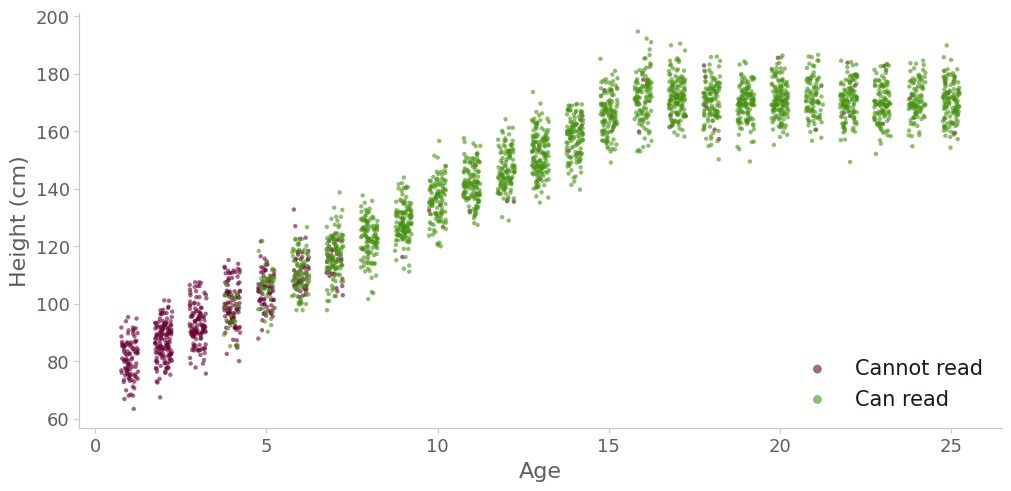

Correlation of height and can_read: 0.71


In [73]:
rng = np.random.default_rng(SEED + 4)
n = 3_000
age = rng.integers(1, 26, n)
height = 75 + 6 * np.minimum(age, 16) + rng.normal(0, 7, n)   # cm: people grow until about 16
can_read = rng.binomial(1, np.clip((age - 3) / 5, 0, 0.98))   # nobody at 3, nearly everybody by 8
people = pd.DataFrame({"age": age, "height": height, "can_read": can_read})

fig, ax = plt.subplots(figsize=(10, 4.8))
for value, color, label in [(0, "#660033", "Cannot read"), (1, "#469110", "Can read")]:
    group = people[people.can_read == value]
    ax.scatter(group.age + rng.uniform(-0.25, 0.25, len(group)), group.height, s=10, alpha=0.6,
               color=color, edgecolor="none", label=label)
ax.set(xlabel="Age", ylabel="Height (cm)")
ax.legend(loc="lower right", markerscale=2)
plt.show()

print(f"Correlation of height and can_read: {people.height.corr(people.can_read):.2f}")

A regression with several regressors is still the best linear predictor, with $\mathbb E[\varepsilon]=\mathbb E[\varepsilon X_k]=0$ for every regressor. Below, `C(age)` gives each age its own indicator, so the slope on `can_read` only compares people of the same age. Section 5 comes back to why we use indicators.

In [74]:
overall = smf.ols("height ~ can_read", data=people).fit(cov_type="HC0")
same_age = smf.ols("height ~ can_read + C(age)", data=people).fit(cov_type="HC0")
print(f"height ~ can_read:           slope = {overall.params['can_read']:6.2f} cm")
print(f"height ~ can_read + C(age):  slope = {same_age.params['can_read']:6.2f} cm (p = {same_age.pvalues['can_read']:.2f})")
print(f"Residual checks: mean = {same_age.resid.mean():.6f}, mean of can_read × residual = {(people.can_read * same_age.resid).mean():.6f}")

# E[Height | Can read, Age] = E[Height | Age], at the ages where both groups exist
by_age = people[people.age.between(4, 7)].pivot_table(index="age", columns="can_read", values="height", aggfunc="mean")
by_age.columns = ["Cannot read", "Can read"]
display(by_age.style.format("{:.1f}"))

height ~ can_read:           slope =  54.11 cm
height ~ can_read + C(age):  slope =   0.38 cm (p = 0.51)
Residual checks: mean = 0.000000, mean of can_read × residual = 0.000000


,Cannot read,Can read
age,,
4,100.1,96.7
5,104.6,105.2
6,111.4,110.6
7,114.3,117.1


## 2. A lottery with a rural preference

---

Back to Lab 7's world, with one change. In the lecture's example, the administrators give rural postcodes double the chance of winning, as a promotion for farmers. Winning is no longer random with respect to $U$, so the natural experiment is ruined. But among rural postcodes, and among urban ones, winning is still random:

$$
S_G\perp U\mid \text{rural}.
$$

Spending follows the same rule as before:

> **spending = `usual` level + local conditions that year + the household's own surprise that year**

- `usual` = €800 + €150 per household member + €300 for a big spender. Big spenders are less common in rural postcodes (20% vs 80%), so rural households tend to spend less, but being rural has no effect of its own.
- This year has two extras: connected postcodes get €300 of favours, and living in a winning postcode adds €150.
- Rural postcodes win with probability 0.90, urban ones with 0.45. We use 200 postcodes this time, so that rural postcodes that lost still exist in reasonable numbers.

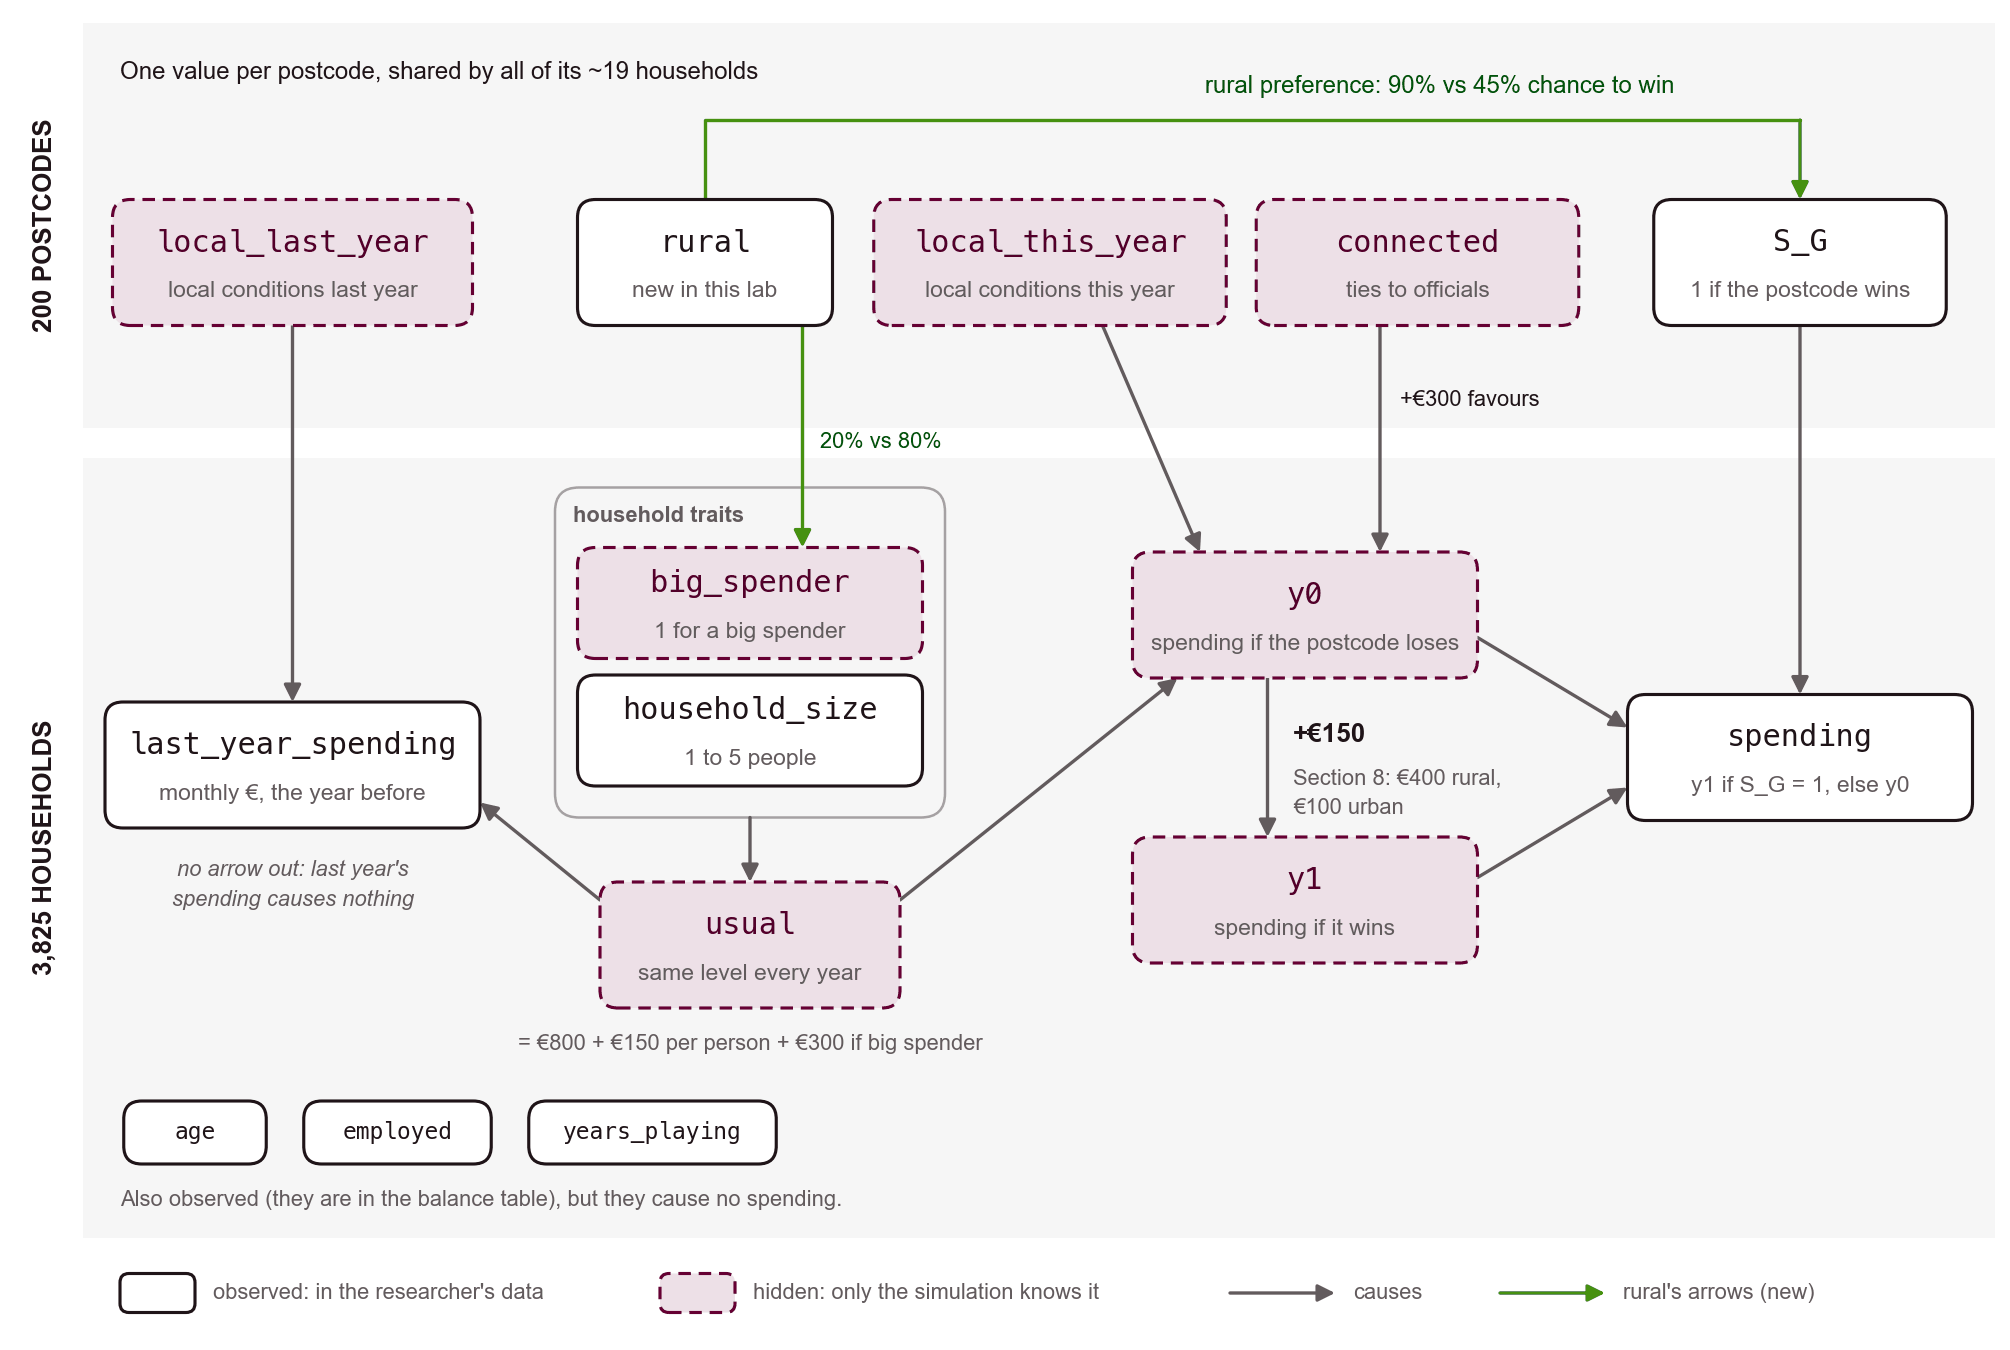

In [75]:
def make_world(n_postcodes, rng, rural_effect=150, urban_effect=150):
    """Lab 7's world, plus one observed postcode trait: rural."""
    households = rng.integers(14, 25, size=n_postcodes)   # 14 to 24 households per postcode
    postcode = np.repeat(np.arange(n_postcodes), households)
    n = len(postcode)

    # Postcode level
    rural = rng.binomial(1, 0.35, n_postcodes)           # observed: new in this lab
    connected = rng.binomial(1, 0.25, n_postcodes)       # UNOBSERVED: ties to lottery officials
    local_last_year = rng.normal(0, 150, n_postcodes)    # UNOBSERVED: a good or bad year for the area (€)
    local_this_year = rng.normal(0, 150, n_postcodes)    # UNOBSERVED

    # Household level
    household_size = rng.integers(1, 6, n)               # 1 to 5 people
    big_spender = rng.binomial(1, np.where(rural[postcode] == 1, 0.2, 0.8))   # UNOBSERVED
    age = rng.integers(20, 81, n)                        # observed, but no effect on spending
    employed = rng.binomial(1, 0.7, n)                   # observed, but no effect on spending
    years_playing = rng.integers(0, 16, n)               # observed, but no effect on spending

    # Monthly spending (€) every year = usual level + local conditions + the household's own surprise
    usual = 800 + 150 * household_size + 300 * big_spender
    last_year_spending = usual + local_last_year[postcode] + rng.normal(0, 200, n)

    # This year, if the postcode loses (y0) and if it wins (y1).
    # Connected postcodes also get favours from the officials this year (+€300), whoever wins.
    y0 = usual + local_this_year[postcode] + rng.normal(0, 200, n) + 300 * connected[postcode]
    y1 = y0 + np.where(rural[postcode] == 1, rural_effect, urban_effect)

    return pd.DataFrame({
        "postcode": postcode, "rural": rural[postcode], "household_size": household_size, "age": age,
        "employed": employed, "years_playing": years_playing,
        "last_year_spending": last_year_spending,
        # columns no researcher would ever see:
        "big_spender": big_spender, "usual": usual, "connected": connected[postcode],
        "local_last_year": local_last_year[postcode], "local_this_year": local_this_year[postcode],
        "y0": y0, "y1": y1,
    })


HIDDEN = ["big_spender", "usual", "connected", "local_last_year", "local_this_year", "y0", "y1"]

world = make_world(200, np.random.default_rng(SEED))
true_effect = (world.y1 - world.y0).mean()

print(f"{len(world):,} lottery players in {world.postcode.nunique()} postcodes, "
      f"{world.groupby('postcode').rural.first().sum()} of them rural")
print(f"True effect of a winning postcode = €{true_effect:.0f}")

3,825 lottery players in 200 postcodes, 72 of them rural
True effect of a winning postcode = €150


In [76]:
def run_lottery(world, rng):
    """Draw winning postcodes and return what a researcher would observe."""
    rural = world.groupby("postcode").rural.first()
    # Rural postcodes get double the chance of winning
    p_win = np.where(rural == 1, 0.90, 0.45)
    wins = rng.binomial(1, p_win)
    data = world.copy()
    data["S_G"] = wins[data.postcode]
    data["spending"] = np.where(data.S_G == 1, data.y1, data.y0)  # only one outcome is ever seen
    return data


lottery = run_lottery(world, np.random.default_rng(SEED + 73))
observed = lottery.drop(columns=HIDDEN)
print(f"Winning postcodes: {lottery.groupby('postcode').S_G.first().sum()} of {lottery.postcode.nunique()}")
observed.sample(5, random_state=SEED)

Winning postcodes: 129 of 200


,postcode,rural,household_size,age,employed,years_playing,last_year_spending,S_G,spending
816,43,1,2,49,0,1,1094.140,1,1743.242
114,5,0,3,29,1,5,1292.961,0,1200.260
3132,164,0,2,43,1,0,1164.230,1,2237.832
815,43,1,3,20,1,11,1965.406,1,1856.604
238,12,0,2,29,1,6,1566.735,0,1559.571


### Question 2: predict before running

1. Will the raw comparison of winners and losers be too high or too low? Why?
2. Within which groups is the comparison plausibly as-if random?

In [77]:
postcode_table = lottery.groupby("rural").agg(
    Postcodes=("postcode", "nunique"), Share_winning=("S_G", "mean"), Big_spenders_hidden=("big_spender", "mean"))
postcode_table.index = ["Urban", "Rural"]
postcode_table.columns = ["Postcodes", "Share winning", "Big spenders (hidden)"]
display(postcode_table.style.format({"Share winning": "{:.0%}", "Big spenders (hidden)": "{:.0%}"}))

raw = clustered("spending ~ S_G", observed)
low, high = raw.conf_int().loc["S_G"]
print(f"Raw winners minus losers: €{raw.params['S_G']:.0f} (clustered 95% CI €{low:.0f} to €{high:.0f}); "
      f"true effect = €{true_effect:.0f}")

,Postcodes,Share winning,Big spenders (hidden)
Urban,128,50%,79%
Rural,72,90%,20%


Raw winners minus losers: €84 (clustered 95% CI €22 to €147); true effect = €150


## 3. Testing the claim: balance given a control

---

If $S_G\perp U\mid C$, then the pieces of $U$ we can see should have no systematic relationship with $S_G$ once $C$ is in the regression:

$$
\text{pre-lottery variable}=\beta_0+\beta_1 S_G+\beta_2 C+e, \qquad \beta_1\approx 0.
$$

This is Lab 7's balance test with the control added. As before, it cannot see unobservables.

### Question 3: predict before running

1. Which pre-lottery variables will look unbalanced in the raw comparison?
2. What will happen to them once `rural` is in the regression?

In [78]:
BALANCE_VARIABLES = ["household_size", "age", "employed", "years_playing", "last_year_spending"]


def balance_table(data):
    """Each pre-lottery variable on S_G: first alone, then with the rural control."""
    rows = []
    for variable in BALANCE_VARIABLES:
        alone = clustered(f"{variable} ~ S_G", data)
        given_rural = clustered(f"{variable} ~ S_G + rural", data)
        rows.append({
            "Pre-lottery variable": variable,
            "Raw difference": alone.params["S_G"], "Raw p-value": alone.pvalues["S_G"],
            "Difference given rural": given_rural.params["S_G"], "p-value given rural": given_rural.pvalues["S_G"],
        })
    return pd.DataFrame(rows)


star = lambda p: f"{p:.3f}" + (" *" if p < 0.05 else "")
display(balance_table(lottery).style.format({"Raw difference": "{:,.2f}", "Difference given rural": "{:,.2f}",
                                             "Raw p-value": star, "p-value given rural": star}).hide(axis="index"))

Pre-lottery variable,Raw difference,Raw p-value,Difference given rural,p-value given rural
household_size,0.04,0.463,0.03,0.605
age,0.31,0.597,0.71,0.260
employed,0.00,0.740,0.01,0.554
years_playing,-0.01,0.945,0.01,0.937
last_year_spending,-95.50,0.000 *,-13.93,0.585


One draw could mislead us, so re-run the lottery 500 times. The lottery is random within rural and urban postcodes every time.

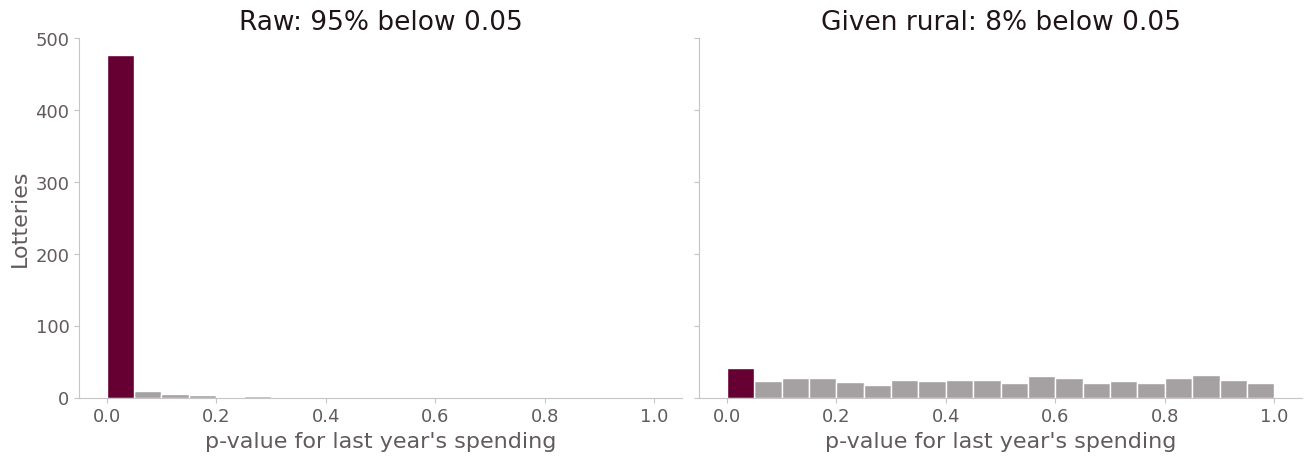

In [79]:
sim_rng = np.random.default_rng(SEED + 2)
raw_p, given_rural_p = [], []
for _ in range(500):
    d = run_lottery(world, sim_rng)
    raw_p.append(clustered("last_year_spending ~ S_G", d).pvalues["S_G"])
    given_rural_p.append(clustered("last_year_spending ~ S_G + rural", d).pvalues["S_G"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, p, name in [(axes[0], np.array(raw_p), "Raw"), (axes[1], np.array(given_rural_p), "Given rural")]:
    ax.hist(p, bins=20, range=(0, 1), color="#A5A1A3", edgecolor="white")
    ax.hist(p[p < 0.05], bins=1, range=(0, 0.05), color="#660033", edgecolor="white")
    ax.set(title=f"{name}: {np.mean(p < 0.05):.0%} below 0.05", xlabel="p-value for last year's spending")
axes[0].set(ylabel="Lotteries")
plt.show()

## 4. Regression with a control

---

Start from the causal model $Y(S_G,U)=\alpha_0+\alpha_1S_G+U$. With a rural preference, $S_G\not\perp U$, so the simple regression is not causal. If $S_G\perp U\mid C$, then $\mathbb E[U\mid S_G,C]=\mathbb E[U\mid C]$, and for a binary control this is linear: $\mathbb E[U\mid C]=\gamma_0+\gamma_1C$. Define

$$
V\equiv U-\mathbb E[U\mid C]
\quad\Longrightarrow\quad
Y=\underbrace{(\alpha_0+\gamma_0)}_{\tilde\alpha_0}+\alpha_1S_G+\underbrace{\gamma_1}_{\tilde\alpha_2}C+V.
$$

The control absorbs the link between $S_G$ and $U$: now $\mathbb E[V]=\mathbb E[S_GV]=\mathbb E[CV]=0$, so OLS recovers $\alpha_1$. This needs three things:

1. $S_G\perp U\mid C$
2. a linear and, for now, homogeneous effect of $S_G$ on $Y$: every household's effect is €150
3. a linear $\mathbb E[U\mid C]$ (automatic when $C$ is binary)

### Question 4: predict before running

1. Being rural has no effect on spending in this world. Will the coefficient on `rural` be zero?

In [80]:
controlled = clustered("spending ~ S_G + rural", observed)
comparison = pd.DataFrame({
    "Estimate": [raw.params["S_G"], controlled.params["S_G"]],
    "Clustered SE": [raw.bse["S_G"], controlled.bse["S_G"]],
    "95% CI lower": [raw.conf_int().loc["S_G", 0], controlled.conf_int().loc["S_G", 0]],
    "95% CI upper": [raw.conf_int().loc["S_G", 1], controlled.conf_int().loc["S_G", 1]],
}, index=["Raw: spending ~ S_G", "Controlled: spending ~ S_G + rural"])
display(comparison.style.format("{:.1f}"))
print(f"True effect = €{true_effect:.0f}")
print(f"Coefficient on rural = {controlled.params['rural']:.0f} euros; rural's own effect on spending = 0 euros")

,Estimate,Clustered SE,95% CI lower,95% CI upper
Raw: spending ~ S_G,84.2,31.8,21.9,146.6
Controlled: spending ~ S_G + rural,146.4,34.7,78.3,214.4


True effect = €150
Coefficient on rural = -154 euros; rural's own effect on spending = 0 euros


The coefficient on `rural` is **not causal**: we only ever defined $\tilde\alpha_2$ descriptively. Here it picks up that big spenders are less common in rural postcodes.

### Checking the moments with the hidden columns

As in Lab 7, the simulation lets us compute $U$, the centred `y0`. Removing its average within rural and urban postcodes gives $V$.

In [81]:
U = lottery.y0 - lottery.y0.mean()
V = U - U.groupby(lottery.rural).transform("mean")
print(f"mean of S_G × U   = {(lottery.S_G * U).mean():7.2f}")
print(f"mean of V         = {abs(V.mean()):7.2f}")
print(f"mean of S_G × V   = {(lottery.S_G * V).mean():7.2f}")
print(f"mean of rural × V = {abs((lottery.rural * V).mean()):7.2f}")

mean of S_G × U   =  -15.07
mean of V         =    0.00
mean of S_G × V   =   -0.70
mean of rural × V =    0.00


## 5. Control from context: adoption

---

Fagereng et al. (2021) ask why wealthy parents have wealthy children: better resources, or genes? Let $S$ be parental wealth and $Y$ the child's adult wealth, with parental genes part of $U$. In general $S\not\perp U$.

After the Korean War, a central agency in Norway matched Korean orphans to approved families in order of application, and families could not choose a child. That links children to parents as-if randomly. One catch: if older, wealthier applicants applied earlier and older children had priority, then timing connects wealth to the child's age at adoption, which is part of $U$. Within a batch of applications, though, who gets which child should be random:

$$
S\perp U\mid \text{year of application}.
$$

The argument comes from knowing how $S$ was assigned, not from the regression.

### Question 5

1. What is $S\perp U\mid$ year in words?
2. Could a balance test prove it?
3. The paper uses an indicator for each year, not one `year` column. Why?

The data below are simulated, with $S=1$ if the parents are wealthy. The true effect is \$12,000.

In [82]:
def make_adoptions(n, rng):
    """Children matched to families in order of application, 1965 to 1968."""
    date = rng.uniform(0, 1460, n)                       # days after 1 January 1965
    cohort = (date // 365).astype(int)
    early = np.array([1, 0.3, 0.1, 0])[cohort]           # earlier batches had older applicants and children
    wealthy = rng.binomial(1, 0.2 + 0.6 * early)
    timing = 36 * early                                  # part of U: effect of the child's age at adoption
    child_wealth = 100 + 12 * wealthy + timing + rng.normal(0, 7, n)     # $000s
    return pd.DataFrame({"date": date, "year": 1965 + cohort, "wealthy": wealthy, "child_wealth": child_wealth})


adoptions = make_adoptions(800, np.random.default_rng(SEED + 71))
display(adoptions.groupby("year")[["wealthy", "child_wealth"]].mean().style.format("{:.2f}"))

rows = []
for label, formula in [("No control", "child_wealth ~ wealthy"),
                       ("year as one number", "child_wealth ~ wealthy + year"),
                       ("An indicator for each year", "child_wealth ~ wealthy + C(year)")]:
    fit = smf.ols(formula, data=adoptions).fit(cov_type="HC0")
    rows.append({"Control": label, "Estimate ($000s)": fit.params["wealthy"], "Robust SE": fit.bse["wealthy"]})
display(pd.DataFrame(rows).style.format({"Estimate ($000s)": "{:.1f}", "Robust SE": "{:.1f}"}).hide(axis="index"))
print("True effect = 12.0")

,wealthy,child_wealth
year,,
1965,0.79,145.45
1966,0.34,115.32
1967,0.27,106.87
1968,0.16,101.82


Control,Estimate ($000s),Robust SE
No control,25.7,1.1
year as one number,14.7,0.7
An indicator for each year,11.9,0.6


True effect = 12.0


## 6. Kitchen-sink regression: military service

---

Angrist (1998) compares military applicants who enlisted with those who did not, controlling for age, years of schooling, application year and AFQT score (the military's test). No quasi-random process is involved: the hope is that the controls capture everything. A causal reading needs

$$
S\perp U\mid \text{age, years of school, application year, AFQT score}.
$$

The lecture's thought experiment: two 20-year-old high-school graduates applied in 1975 with similar scores. One enlists. The other is rejected, or has something better to do. Are they identical apart from serving?

### Question 6

1. Give one part of $U$ that could break the claim.
2. As we add controls one at a time, will the estimate move steadily toward the truth?
3. If you don't believe the claim, what does the coefficient on enlisting describe?

The data below are simulated: enlisting raises later income by \$3,000, and each applicant has a hidden outside option (a job offer, a college place). In real data we could not add that last column.

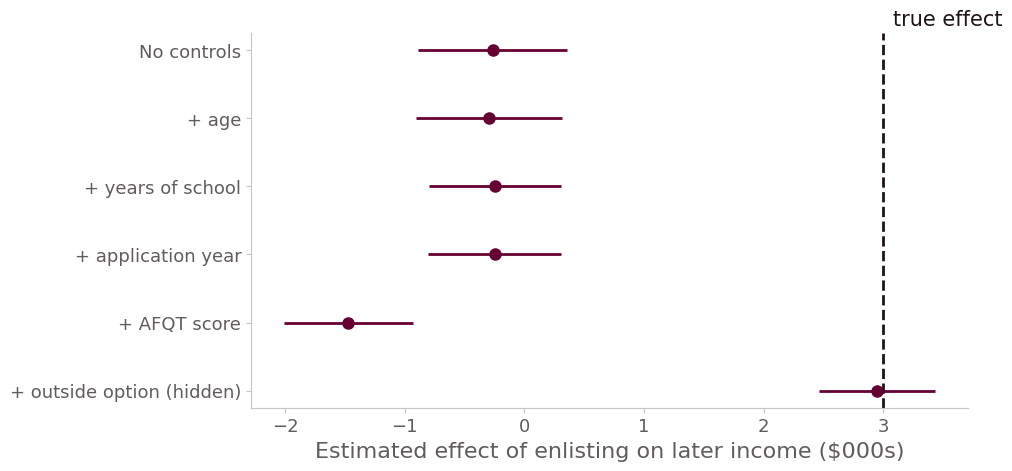

Controls,Estimate,Lower,Upper
No controls,-0.26,-0.89,0.36
+ age,-0.29,-0.90,0.31
+ years of school,-0.25,-0.80,0.31
+ application year,-0.25,-0.80,0.30
+ AFQT score,-1.47,-2.01,-0.93
+ outside option (hidden),2.95,2.46,3.44


In [83]:
def make_applicants(n, rng):
    """Military applicants, whether they enlist, and their later income ($000s)."""
    age = rng.integers(18, 25, n)
    school = rng.integers(9, np.minimum(age - 5, 17))    # at most age - 6 years, up to 16
    year = rng.integers(1975, 1982, n)
    # More school, higher scores
    afqt = np.clip(np.round(50 + 4 * (school - 12) + 15 * rng.normal(size=n)), 1, 99).astype(int)
    outside_option = rng.normal(size=n)                  # UNOBSERVED: better options outside the military
    # The military prefers high scorers; people with better options often decline
    index = -0.3 + 0.045 * (afqt - 50) - 0.2 * (school - 12) - 1.1 * outside_option
    enlist = rng.binomial(1, 1 / (1 + np.exp(-index)))
    income = (30 + 3 * enlist + 0.25 * (age - 21) + 1.2 * (school - 12) + 0.14 * (afqt - 50)
              + 5 * outside_option + rng.normal(0, 6, n))
    return pd.DataFrame({"age": age, "school": school, "year": year, "afqt": afqt,
                         "outside_option": outside_option, "enlist": enlist, "income": income})


applicants = make_applicants(3_000, np.random.default_rng(SEED + 16))

controls = [("No controls", ""), ("+ age", " + age"), ("+ years of school", " + school"),
            ("+ application year", " + C(year)"), ("+ AFQT score", " + afqt"),
            ("+ outside option (hidden)", " + outside_option")]
rows, formula = [], "income ~ enlist"
for label, term in controls:
    formula += term
    fit = smf.ols(formula, data=applicants).fit(cov_type="HC0")
    rows.append({"Controls": label, "Estimate": fit.params["enlist"],
                 "Lower": fit.conf_int().loc["enlist", 0], "Upper": fit.conf_int().loc["enlist", 1]})
path = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(path))[::-1]
ax.errorbar(path.Estimate, y, xerr=[path.Estimate - path.Lower, path.Upper - path.Estimate],
            fmt="o", ms=8, capsize=0, color="#660033", lw=2)
ax.axvline(3, color="#1F1418", ls="--", lw=2)
ax.text(3.08, len(path) - 0.55, "true effect", va="center", color="#1F1418")
ax.set_yticks(y, path.Controls)
ax.set(xlabel="Estimated effect of enlisting on later income ($000s)")
plt.show()
display(path.style.format({"Estimate": "{:.2f}", "Lower": "{:.2f}", "Upper": "{:.2f}"}).hide(axis="index"))

More controls are not automatically better. Here the raw estimate has two biases pulling in opposite directions: high scorers enlist more and earn more (+), while people with good outside options decline and earn more (−). Controlling for AFQT removes only the first, so the estimate moves **further** from the truth. In real data we would never see the dashed line.

## 7. Exact matching

---

Matching rests on the same assumption, $S\perp U\mid C$. Within each group defined by the controls, $S$ is as good as random, so each group is a small natural experiment. Compare treated and untreated within each group, then weight by the size of the group:

$$
\widehat{ATE}^m=\sum_{k=1}^{K}\left(\hat{\mathbb E}[Y\mid S=1,C=c_k]-\hat{\mathbb E}[Y\mid S=0,C=c_k]\right)\hat P(C=c_k).
$$

For the lottery with a rural preference, as the lecture says, this is just six sample means put together.

In [84]:
rural_winners = observed[(observed.rural == 1) & (observed.S_G == 1)].spending.mean()
rural_losers = observed[(observed.rural == 1) & (observed.S_G == 0)].spending.mean()
urban_winners = observed[(observed.rural == 0) & (observed.S_G == 1)].spending.mean()
urban_losers = observed[(observed.rural == 0) & (observed.S_G == 0)].spending.mean()
share_rural = (observed.rural == 1).mean()
share_urban = (observed.rural == 0).mean()
ate_hat = (rural_winners - rural_losers) * share_rural + (urban_winners - urban_losers) * share_urban

print(f"Exact matching:        €{ate_hat:.1f}")
print(f"Controlled regression: €{controlled.params['S_G']:.1f}")
print(f"True effect:           €{true_effect:.1f}")

Exact matching:        €155.1
Controlled regression: €146.4
True effect:           €150.0


### Question 7

1. Exact matching needs at least one treated and one untreated unit in every group. In the lottery case what could go wrong?
2. In the table below, which group makes this estimate least precise?

In [85]:
def exact_match(data):
    """The same six means in one go."""
    means = data.pivot_table(index="rural", columns="S_G", values="spending", aggfunc="mean")
    shares = data.rural.value_counts(normalize=True)
    return ((means[1] - means[0]) * shares).sum(skipna=False)


groups = observed.groupby(["rural", "S_G"]).agg(
    Postcodes=("postcode", "nunique"), Households=("postcode", "size"), Mean_spending=("spending", "mean"))
display(groups.rename(columns={"Mean_spending": "Mean spending"}).style.format({"Mean spending": "{:,.1f}"}))
print(f"exact_match(observed) = €{exact_match(observed):.1f}")

exact_match(observed) = €155.1


### When exact matching runs out of data

With many controls, or controls with many values, some groups contain only treated or only untreated people. This is the curse of dimensionality. Suppose we were willing to believe the claim for military applicants. Maybe our sample has only one 20-year-old with 11 years of school who applied in 1975 and scored 83, and that person didn't enlist. What can we compare them with?

In [86]:
rows = []
for columns in (["age"], ["age", "school"], ["age", "school", "year"], ["age", "school", "year", "afqt"]):
    counts = applicants.groupby(columns).enlist.agg(["size", "sum"])
    both = (counts["sum"] > 0) & (counts["sum"] < counts["size"])
    rows.append({"Controls": " + ".join(columns), "Groups in the data": len(counts),
                 "Groups with both enlisted and not": both.mean(),
                 "Applicants we can use": counts["size"][both].sum() / len(applicants)})
display(pd.DataFrame(rows).style.format({"Groups in the data": "{:,}", "Groups with both enlisted and not": "{:.0%}",
                                         "Applicants we can use": "{:.0%}"}).hide(axis="index"))

Controls,Groups in the data,Groups with both enlisted and not,Applicants we can use
age,7,100%,100%
age + school,46,100%,100%
age + school + year,321,97%,99%
age + school + year + afqt,"2,723",5%,9%


## 8. Regression vs matching when effects differ

---

So far every household's effect was €150, and regression and matching agreed. Now let the prize do more in rural postcodes: **€400 in rural postcodes, €100 in urban ones**. Same households, same draw; only `y1` changes.

Matching still targets the ATE, because it weights each group by its size. Regression with a control estimates a differently weighted average:

$$
\alpha_1=\sum_{k=1}^{K}\mathbb E[Y(S=1,U)-Y(S=0,U)\mid C=c_k]\,W(C=c_k),
\qquad W(C=c_k)\propto P(C=c_k)\operatorname{Var}(S\mid C=c_k).
$$

It learns most about groups with a lot of variation in $S$, "where the action is".

### Question 8: predict before running

1. Which group has more variance in $S_G$?
2. Will the regression estimate be above or below the true ATE?

In [87]:
world_2 = make_world(200, np.random.default_rng(SEED), rural_effect=400, urban_effect=100)
lottery_2 = run_lottery(world_2, np.random.default_rng(SEED + 73))
true_ate = (world_2.y1 - world_2.y0).mean()
regression_2 = clustered("spending ~ S_G + rural", lottery_2)

print(f"Controlled regression: €{regression_2.params['S_G']:.0f}")
print(f"Exact matching:        €{exact_match(lottery_2):.0f}")
print(f"True ATE:              €{true_ate:.0f}")

Controlled regression: €147
Exact matching:        €214
True ATE:              €209


We can rebuild both numbers from the same two within-group differences. Only the weights differ.

In [88]:
weights = lottery_2.groupby("rural").agg(Share=("S_G", "size"), P_win=("S_G", "mean"))
weights["Share"] /= len(lottery_2)
weights["Var_S"] = weights.P_win * (1 - weights.P_win)
weights["Regression_weight"] = weights.Share * weights.Var_S / (weights.Share * weights.Var_S).sum()
means = lottery_2.pivot_table(index="rural", columns="S_G", values="spending", aggfunc="mean")
weights["Within_difference"] = means[1] - means[0]
weights.index = ["Urban", "Rural"]
display(weights.rename(columns={"Share": "Share of households", "P_win": "P(win)", "Var_S": "Var(S_G)",
                                "Regression_weight": "Regression weight", "Within_difference": "Within-group difference"})
        .style.format({"Share of households": "{:.3f}", "P(win)": "{:.3f}", "Var(S_G)": "{:.3f}",
                       "Regression weight": "{:.3f}", "Within-group difference": "{:.1f}"}))

print(f"Regression weights × differences = {(weights.Regression_weight * weights.Within_difference).sum():.2f}; "
      f"OLS coefficient = {regression_2.params['S_G']:.2f}")
print(f"Shares × differences             = {(weights.Share * weights.Within_difference).sum():.2f}; "
      f"exact matching = {exact_match(lottery_2):.2f}")

,Share of households,P(win),Var(S_G),Regression weight,Within-group difference
Urban,0.638,0.500,0.250,0.830,88.6
Rural,0.362,0.900,0.090,0.170,434.1


Regression weights × differences = 147.41; OLS coefficient = 147.41
Shares × differences             = 213.79; exact matching = 213.79


Regression can also be adjusted to target the ATE. An interaction lets the effect differ by group, and weighting the two effects by group size gives the matching estimate exactly, along with a clustered standard error.

In [89]:
interaction = clustered("spending ~ S_G * rural", lottery_2)
ate_test = interaction.t_test(f"S_G + {lottery_2.rural.mean()} * S_G:rural = 0")
low, high = ate_test.conf_int()[0]
print(f"Urban effect: €{interaction.params['S_G']:.0f};  rural effect: €{interaction.params['S_G'] + interaction.params['S_G:rural']:.0f}")
print(f"Size-weighted effect: €{ate_test.effect[0]:.0f} (clustered SE {ate_test.sd[0][0]:.0f}, 95% CI €{low:.0f} to €{high:.0f})")

Urban effect: €89;  rural effect: €434
Size-weighted effect: €214 (clustered SE 44, 95% CI €128 to €300)


### Re-run the lottery 1,000 times

One draw can land anywhere, so keep the same households and re-run only the draw.

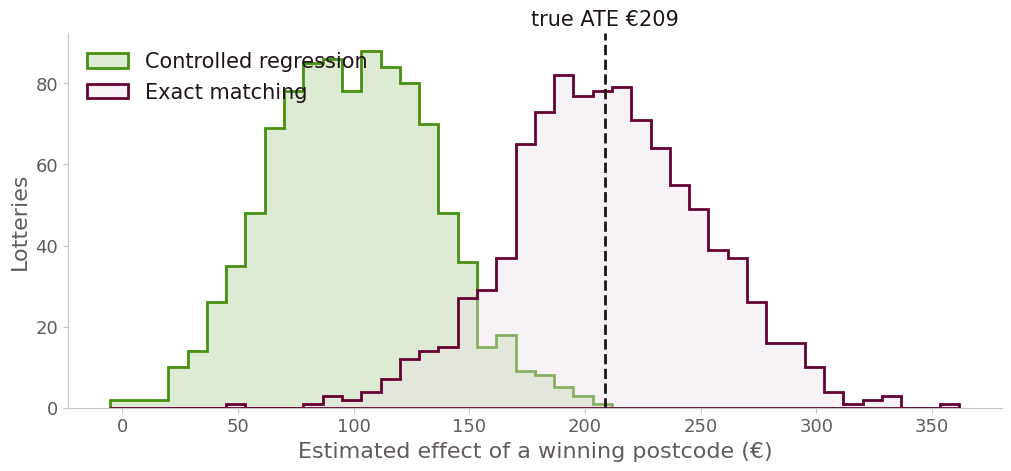

Controlled regression: mean €100, SD €35
Exact matching:        mean €210, SD €42
Matching closer to the true ATE in 94% of lotteries


In [90]:
sim_rng = np.random.default_rng(SEED + 7)
rows = []
for _ in range(1000):
    d = run_lottery(world_2, sim_rng)
    rows.append({"regression": smf.ols("spending ~ S_G * rural", data=d).fit().params["S_G"],
                 "matching": exact_match(d)})
reruns = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.6))
bins = np.linspace(reruns.min().min(), reruns.max().max(), 45)
ax.hist(reruns.regression, bins=bins, histtype="stepfilled", facecolor="#DEEBD4", edgecolor="#469110", lw=2, label="Controlled regression")
ax.hist(reruns.matching, bins=bins, histtype="stepfilled", facecolor="#EDE0E766", edgecolor="#660033", lw=2, label="Exact matching")
ax.axvline(true_ate, color="#1F1418", ls="--", lw=2)
ax.text(true_ate, ax.get_ylim()[1] * 1.01, f"true ATE €{true_ate:.0f}", ha="center", va="bottom", color="#1F1418")
ax.set(xlabel="Estimated effect of a winning postcode (€)", ylabel="Lotteries")
ax.legend(loc="upper left")
plt.show()

print(f"Controlled regression: mean €{reruns.regression.mean():.0f}, SD €{reruns.regression.std():.0f}")
print(f"Exact matching:        mean €{reruns.matching.mean():.0f}, SD €{reruns.matching.std():.0f}")
print(f"Matching closer to the true ATE in {np.mean((reruns.matching - true_ate).abs() < (reruns.regression - true_ate).abs()):.0%} of lotteries")

## 9. Nearest-neighbor matching

---

Back to adoption, with a finer control: $C$ = the exact application date. If only one family applied on 7 June 1966, and they were wealthy, there is nobody to compare them with on that date, so exact matching fails. **Nearest-neighbor matching** pairs each treated unit with the untreated unit whose control is closest, here the fewest days apart, and averages the differences over the $t$ treated units:

$$
\frac{1}{t}\sum_{i=1}^{t}\left(Y_{i_t}(S=1,U)-Y_{i_u}(S=0,U)\right).
$$

The closer the matches, the less bias we expect.

### Question 9: predict before running

1. Will it come closer to the true \$12,000 than year indicators did?
2. What should happen to the distance between matches as the sample grows?
3. Why would a far-away neighbor create bias even if $S\perp U\mid C$ holds?

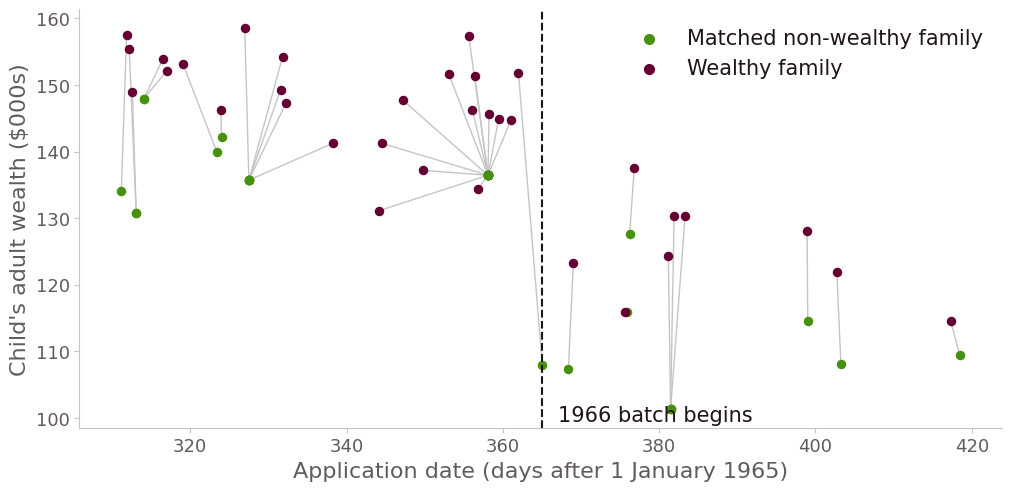

Nearest-neighbor estimate: 12.2; true effect = 12.0
Average distance between matches: 2.5 days


In [91]:
def nearest_neighbor_pairs(data):
    """For each wealthy family, the non-wealthy family with the closest application date."""
    treated, untreated = data[data.wealthy == 1], data[data.wealthy == 0]
    days_apart = np.abs(treated.date.to_numpy()[:, None] - untreated.date.to_numpy())
    nearest = untreated.iloc[days_apart.argmin(axis=1)]
    return pd.DataFrame({"treated_date": treated.date.to_numpy(), "treated_wealth": treated.child_wealth.to_numpy(),
                         "match_date": nearest.date.to_numpy(), "match_wealth": nearest.child_wealth.to_numpy()})


pairs = nearest_neighbor_pairs(adoptions)
window = pairs[pairs.treated_date.between(310, 420)]

fig, ax = plt.subplots(figsize=(10, 4.8))
for _, row in window.iterrows():
    ax.plot([row.treated_date, row.match_date], [row.treated_wealth, row.match_wealth], color="#C7C4C5", lw=1, zorder=1)
ax.scatter(window.match_date, window.match_wealth, s=34, color="#469110", zorder=2, label="Matched non-wealthy family")
ax.scatter(window.treated_date, window.treated_wealth, s=34, color="#660033", zorder=3, label="Wealthy family")
ax.axvline(365, color="#1F1418", ls="--", lw=1.5)
ax.text(367, ax.get_ylim()[0] + 1, "1966 batch begins", color="#1F1418")
ax.set(xlabel="Application date (days after 1 January 1965)", ylabel="Child's adult wealth ($000s)")
ax.legend(loc="upper right", markerscale=1.2)
plt.show()

print(f"Nearest-neighbor estimate: {(pairs.treated_wealth - pairs.match_wealth).mean():.1f}; true effect = 12.0")
print(f"Average distance between matches: {(pairs.treated_date - pairs.match_date).abs().mean():.1f} days")

Larger samples usually mean more precise estimates. With inexact matching, they also mean closer matches and less bias, so sample size becomes an identification issue. Let's check.

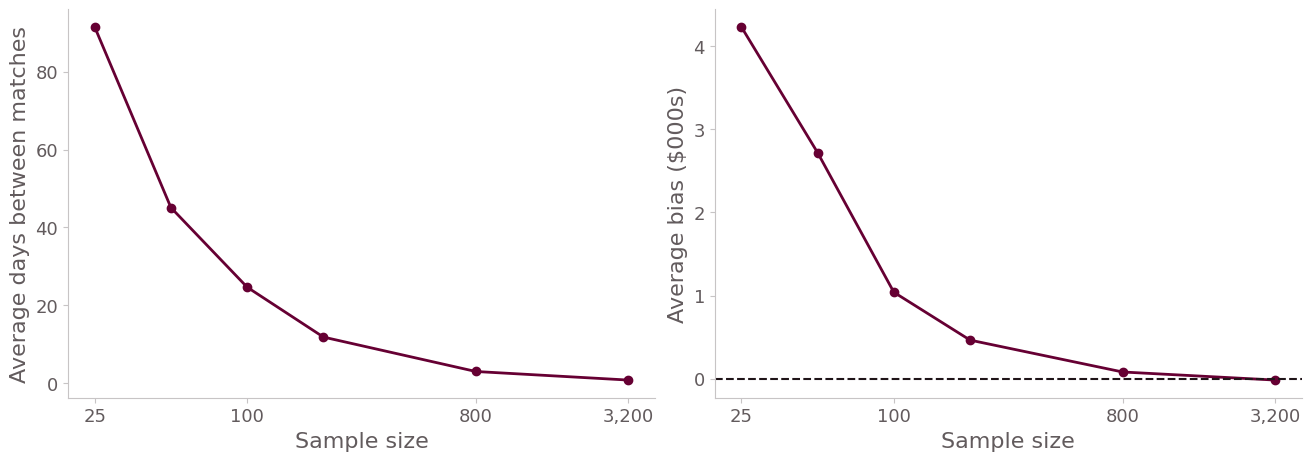

Sample size,Days apart,Bias
25,91.5,+4.23
50,45.1,+2.72
100,24.6,+1.04
200,11.8,+0.46
800,2.9,+0.08
3200,0.7,-0.02


In [92]:
sim_rng = np.random.default_rng(SEED + 8)
rows = []
for n, reps in [(25, 400), (50, 400), (100, 400), (200, 400), (800, 200), (3200, 50)]:
    estimates, distances = [], []
    for _ in range(reps):
        p = nearest_neighbor_pairs(make_adoptions(n, sim_rng))
        estimates.append((p.treated_wealth - p.match_wealth).mean())
        distances.append((p.treated_date - p.match_date).abs().mean())
    rows.append({"Sample size": n, "Days apart": np.mean(distances), "Bias": np.mean(estimates) - 12})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
axes[0].plot(sweep["Sample size"], sweep["Days apart"], "o-", color="#660033", lw=2)
axes[0].set(xscale="log", xlabel="Sample size", ylabel="Average days between matches")
axes[1].plot(sweep["Sample size"], sweep["Bias"], "o-", color="#660033", lw=2)
axes[1].axhline(0, color="#1F1418", ls="--", lw=1.5)
axes[1].set(xscale="log", xlabel="Sample size", ylabel="Average bias ($000s)")
axes[1].set_xticks([25, 100, 800, 3200], ["25", "100", "800", "3,200"])
axes[1].minorticks_off()
plt.show()
display(sweep.style.format({"Days apart": "{:.1f}", "Bias": "{:+.2f}"}).hide(axis="index"))